In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier, KernelDensity
from sklearn.metrics import ConfusionMatrixDisplay

class KDEClassifier(BaseEstimator, ClassifierMixin):
    """Bayes classifier: one KDE per class, predict argmax_y log p(x|y) + log p(y)."""
    def __init__(self, bandwidth=0.5):
        self.bandwidth = bandwidth
    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.classes_ = np.unique(y)
        self.kdes_ = [KernelDensity(bandwidth=self.bandwidth).fit(X[y == c]) for c in self.classes_]
        self.log_priors_ = np.log([np.mean(y == c) for c in self.classes_])
        return self
    def predict(self, X):
        lp = np.column_stack([k.score_samples(np.asarray(X)) for k in self.kdes_]) + self.log_priors_
        return self.classes_[lp.argmax(axis=1)]

models = {
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.1),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(gamma="scale")),
    "kNN (k=7)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "KDE-Bayes": make_pipeline(StandardScaler(), KDEClassifier(bandwidth=0.5)),
}

train = pd.read_csv("train.csv")
X, y = train.drop(columns=["id", "target"]), train["target"]
classes = np.unique(y)
colors = dict(zip(classes, ["#1f77b4", "#ff7f0e", "#2ca02c"]))

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0)
scores = {n: cross_val_score(m, X, y, cv=cv) for n, m in models.items()}
for n, s in scores.items():
    print(f"{n:10s} {s.mean():.3f} ± {s.std():.3f}")

LDA        0.967 ± 0.053
QDA        0.950 ± 0.063
LogReg     0.934 ± 0.072
SVM-RBF    0.936 ± 0.065
kNN (k=7)  0.926 ± 0.072
KDE-Bayes  0.927 ± 0.067


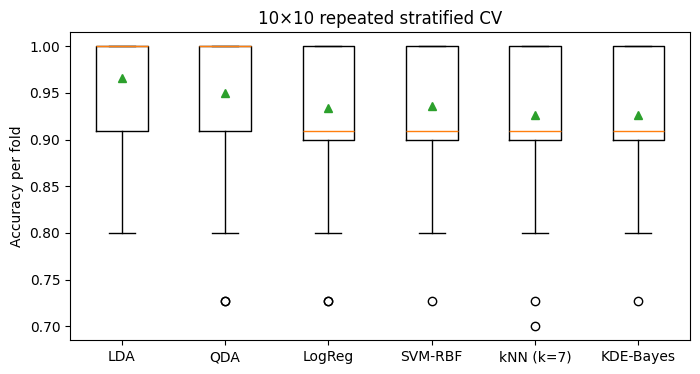

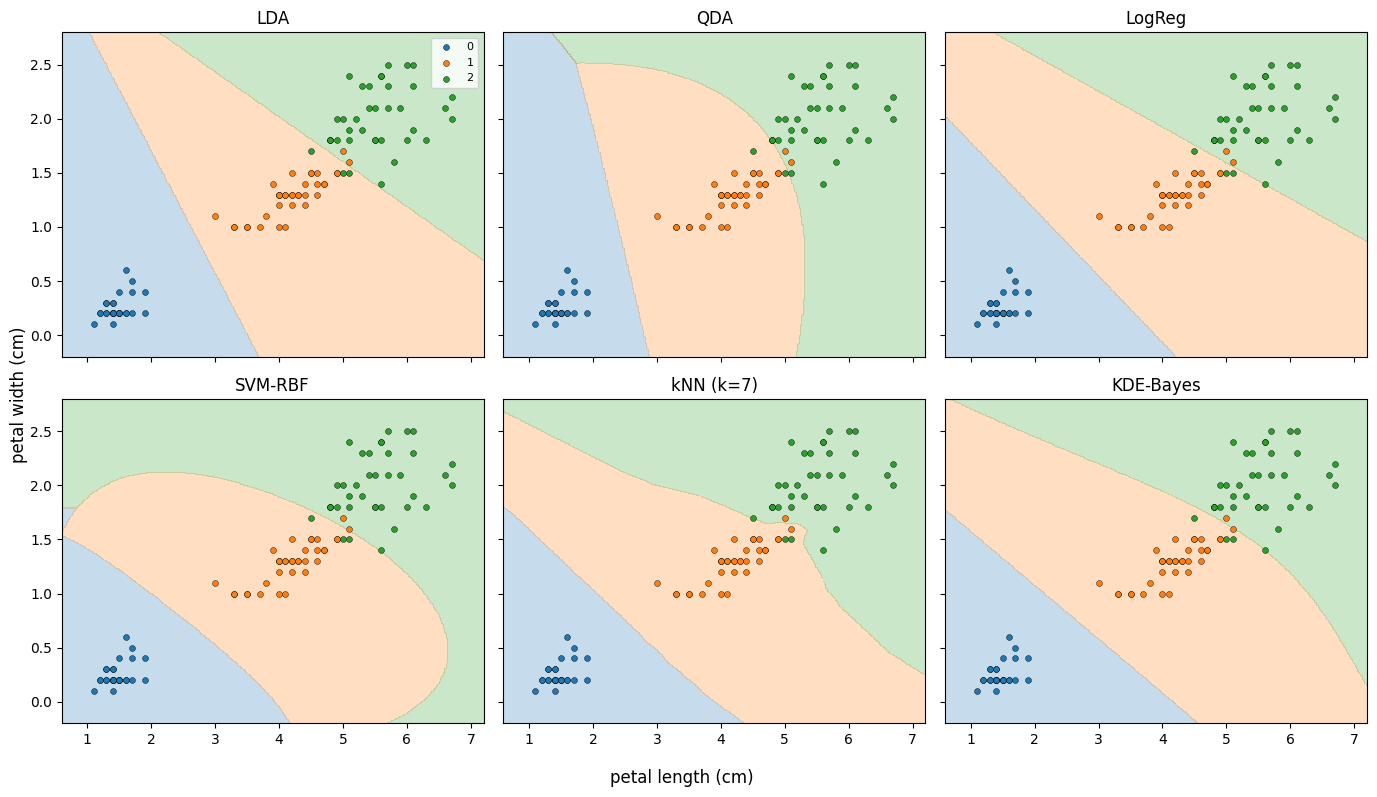

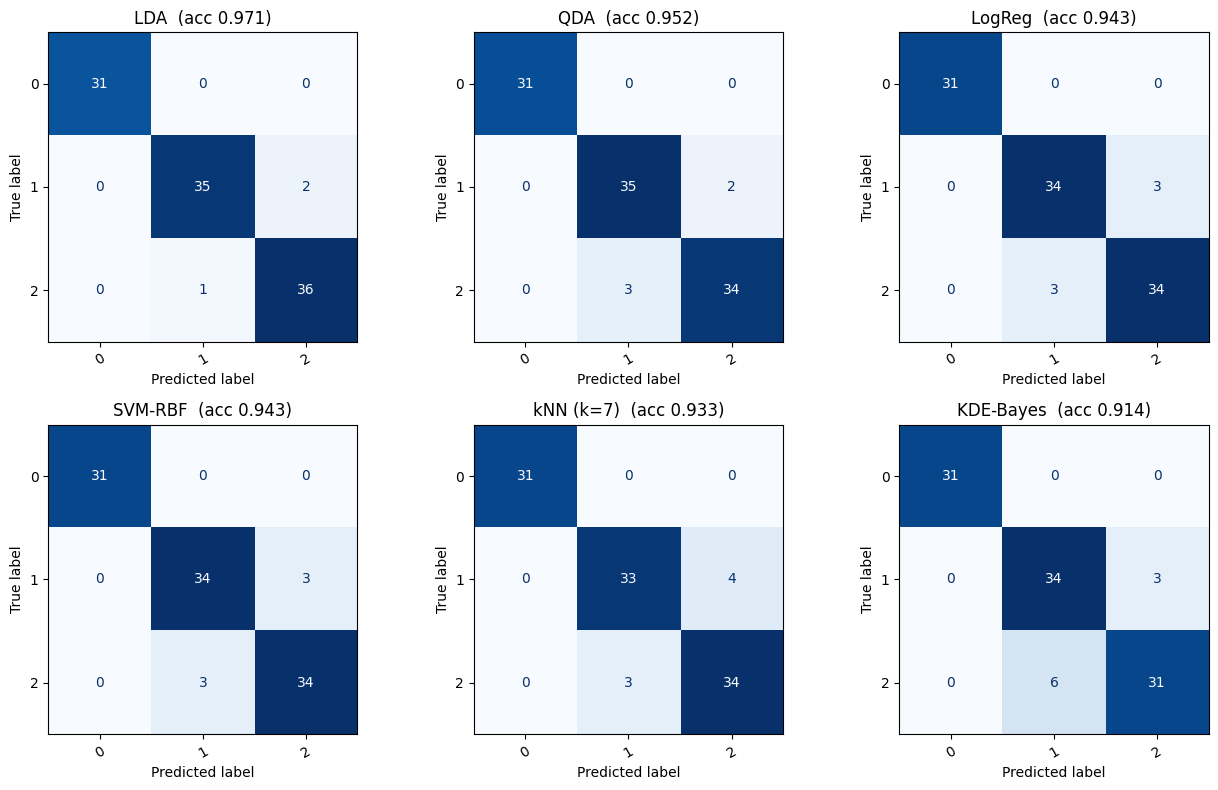

In [3]:
# 1. CV score distributions
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(list(scores.values()), showmeans=True)
ax.set_xticks(range(1, len(scores) + 1), list(scores))
ax.set_ylabel("Accuracy per fold"); ax.set_title("10×10 repeated stratified CV")
plt.show()

# 2. Decision regions on the petal features
f1, f2 = "petal length (cm)", "petal width (cm)"
X2 = X[[f1, f2]].values
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - .5, X2[:, 0].max() + .5, 300),
                     np.linspace(X2[:, 1].min() - .3, X2[:, 1].max() + .3, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
idx = {c: i for i, c in enumerate(classes)}

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
for ax, (n, m) in zip(axes.ravel(), models.items()):
    m.fit(X2, y)
    Z = np.vectorize(idx.get)(m.predict(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, levels=[-.5, .5, 1.5, 2.5], colors=list(colors.values()))
    for c in classes:
        mk = (y == c).values
        ax.scatter(X2[mk, 0], X2[mk, 1], s=18, c=colors[c], edgecolor="k", lw=.3, label=c)
    ax.set_title(n)
axes[0, 0].legend(fontsize=8)
fig.supxlabel(f1); fig.supylabel(f2)
plt.tight_layout(); plt.show()

# 3. Out-of-fold confusion matrices (all 4 features)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (n, m) in zip(axes.ravel(), models.items()):
    yp = cross_val_predict(m, X, y, cv=cv5)
    ConfusionMatrixDisplay.from_predictions(y, yp, ax=ax, colorbar=False, xticks_rotation=30, cmap="Blues")
    ax.set_title(f"{n}  (acc {np.mean(yp == y):.3f})")
plt.tight_layout(); plt.show()